In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
from datetime import date
from sklearn.metrics import auc
import random

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [3]:
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)

In [4]:
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
# decomp_Mixture = decomp_Mixture.T

In [5]:
print(decomp_Basis.shape)
print(decomp_Mixture.shape)

(733, 16)
(16, 3591898)


In [5]:
dhs_array = dhs.to_numpy()

In [6]:
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

In [7]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [8]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
#first bigwig file
# GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF691MRD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

#second bigwig file
GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF962FBP.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

GM06990_signal[['name']] = GM06990_signal[['name']].astype(str)
GM06990_signal = GM06990_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
GM06990_signal = GM06990_signal.reindex(id_order)
GM06990_signal = GM06990_signal.reset_index()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [9]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
h7_hesc_t14_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF682ATU.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])
h7_hesc_t14_signal[['name']] = h7_hesc_t14_signal[['name']].astype(str)
h7_hesc_t14_signal = h7_hesc_t14_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
h7_hesc_t14_signal = h7_hesc_t14_signal.reindex(id_order)
h7_hesc_t14_signal = h7_hesc_t14_signal.reset_index()

In [10]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
f_eye_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF967FUD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])
f_eye_signal[['name']] = f_eye_signal[['name']].astype(str)
f_eye_signal = f_eye_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
f_eye_signal = f_eye_signal.reindex(id_order)
f_eye_signal = f_eye_signal.reset_index()

In [26]:
rec_info_GM06990 = sample_recommendation(['GM06990'], GM06990_signal, print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
      chr11:110201459-110201620 | Tissue invariant | 688 | 0.877/2.833 | N/A | N/A
      chr17:8410360-8410560 | Tissue invariant | 707 | 0.813/3.276 | N/A | N/A
      chr1:248906428-248906799 | Tissue invariant | 713 | 4.982/4.91 | 12.514/4.274 | N/A
      chr5:150561043-150561202 | Tissue invariant | 654 | 0.909/3.34 | N/A | N/A
      chr19:57435140-57435360 | Tissue invariant | 732 | 2.896/9.453 | N/A | N/A


In [29]:
#finding AUC values for each component
GM06990_auc = []
for j in range(len(GM06990_all_comps_precision)):
    GM06990_auc.append(auc(GM06990_all_comps_recall[j], GM06990_all_comps_precision[j]))

In [30]:
#finding top AUC non-tissue invariant component
GM06990_top_comp = []
ind = GM06990_auc.index(max(GM06990_auc[1:]))
GM06990_top_comp.append(comps[ind])

In [32]:
#filtering rec info for only non-tissue invariant component with top AUC
top_comp_GM06990_rec_info = []
top_comp_GM06990_rec_info.append(filter_in_recs(rec_info_GM06990[0], GM06990_top_comp))

In [33]:
biosample = 0
biosample_name = 'GM06990'
print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_GM06990_rec_info[0])
print(link_path)

Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_filtered_recs_CT20211118.bed


In [18]:
rec_info_h7_hesc_t14 = sample_recommendation(['H7_hESC_T14'], h7_hesc_t14_signal, print_num=5)

Biosample: H7_hESC_T14 (41)
   Number of Known DHSs: 53784

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
      chr1:33127240-33127540 | Tissue invariant | 726 | 0.149/12.305 | N/A | N/A
      chr19:12294800-12295040 | Tissue invariant | 729 | 0.086/7.15 | N/A | N/A
      chr19:12401180-12401460 | Tissue invariant | 727 | 0.111/6.433 | N/A | N/A
      chr8:119832760-119832946 | Tissue invariant | 724 | 0.747/5.185 | N/A | N/A
      chr19:37172680-37172920 | Tissue invariant | 726 | 0.103/7.304 | N/A | N/A


In [34]:
#finding AUC values for each component
h7_hesc_t14_auc = []
for j in range(len(h7_hesc_t14_all_comps_precision)):
    h7_hesc_t14_auc.append(auc(h7_hesc_t14_all_comps_recall[j], h7_hesc_t14_all_comps_precision[j]))

In [35]:
#finding top AUC non-tissue invariant component
h7_hesc_t14_top_comp = []
ind = h7_hesc_t14_auc.index(max(h7_hesc_t14_auc[1:]))
h7_hesc_t14_top_comp.append(comps[ind])

In [36]:
#filtering rec info for only non-tissue invariant component with top AUC
top_comp_h7_hesc_t14_rec_info = []
top_comp_h7_hesc_t14_rec_info.append(filter_in_recs(rec_info_h7_hesc_t14[0], h7_hesc_t14_top_comp))

In [37]:
biosample = 41
biosample_name = 'h7_hesc_t14'
print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_h7_hesc_t14_rec_info[0])
print(link_path)

Biosample: h7_hesc_t14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h7_hesc_t14_41_filtered_recs_CT20211118.bed


In [19]:
#filtering rec info for only cardiac component with top AUC
top_comp_h7_hesc_t14_rec_info = []
top_comp_h7_hesc_t14_rec_info.append(filter_in_recs(rec_info_h7_hesc_t14[0], ['Cardiac']))

In [20]:
biosample = 41
biosample_name = 'h7_hesc_t14'
print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_h7_hesc_t14_rec_info[0])
print(link_path)

Biosample: h7_hesc_t14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h7_hesc_t14_41_filtered_recs_CT20211119.bed


In [21]:
rec_info_f_eye = sample_recommendation(['fEye'], f_eye_signal, print_num=5)

Biosample: fEye (561)
   Number of Known DHSs: 231311

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
      chr13:84866020-84866200 | Organ devel. / renal | 226 | 0.348/1.141 | 0.38/0.729 | N/A
      chr3:159839855-159840082 | Primitive / embryonic | 159 | 3.239/2.574 | 3.415/1.45 | N/A
      chr11:27718414-27718740 | Stromal A | 278 | 1.31/3.786 | N/A | 1.359/1.346
      chr21:46605080-46605340 | Neural | 111 | 0.379/1.482 | 0.251/0.301 | 0.428/0.821
      chr6:87796617-87796802 | Primitive / embryonic | 437 | 0.296/1.33 | N/A | N/A


In [40]:
#finding AUC values for each component
fEye_auc = []
for j in range(len(f_eye_all_comps_precision)):
    fEye_auc.append(auc(f_eye_all_comps_recall[j], f_eye_all_comps_precision[j]))

In [41]:
#finding top AUC non-tissue invariant component
fEye_top_comp = []
ind = fEye_auc.index(max(fEye_auc[1:]))
fEye_top_comp.append(comps[ind])

In [42]:
#filtering rec info for only non-tissue invariant component with top AUC
top_comp_fEye_rec_info = []
top_comp_fEye_rec_info.append(filter_in_recs(rec_info_f_eye[0], fEye_top_comp))

In [43]:
biosample = 561
biosample_name = 'fEye'
print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_fEye_rec_info[0])
print(link_path)

Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_filtered_recs_CT20211118.bed


In [22]:
#filtering rec info for only Primitive / embryonic component
top_comp_fEye_rec_info = []
top_comp_fEye_rec_info.append(filter_in_recs(rec_info_f_eye[0], ['Primitive / embryonic']))

In [23]:
biosample = 561
biosample_name = 'fEye'
print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_fEye_rec_info[0])
print(link_path)

Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_filtered_recs_CT20211119.bed


In [134]:
# rec_info_100 = sample_recommendation(list(range(100)), f_eye_signal, print_num=0)

In [14]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_100.pickle', 'wb')
pickle.dump(rec_info_100, pickle_out)
pickle_out.close()

In [135]:
# rec_info_200 = sample_recommendation(list(range(100, 200)), f_eye_signal, print_num=0)

In [16]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_200.pickle', 'wb')
pickle.dump(rec_info_200, pickle_out)
pickle_out.close()

In [136]:
# rec_info_300 = sample_recommendation(list(range(200, 300)), f_eye_signal, print_num=0)

In [18]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_300.pickle', 'wb')
pickle.dump(rec_info_300, pickle_out)
pickle_out.close()

In [137]:
# rec_info_400 = sample_recommendation(list(range(300, 400)), f_eye_signal, print_num=0)

In [20]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_400.pickle', 'wb')
pickle.dump(rec_info_400, pickle_out)
pickle_out.close()

In [138]:
# rec_info_500 = sample_recommendation(list(range(400, 500)), f_eye_signal, print_num=0)

In [22]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_500.pickle', 'wb')
pickle.dump(rec_info_500, pickle_out)
pickle_out.close()

In [139]:
# rec_info_600 = sample_recommendation(list(range(500, 600)), f_eye_signal, print_num=0)

In [24]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_600.pickle', 'wb')
pickle.dump(rec_info_600, pickle_out)
pickle_out.close()

In [140]:
# rec_info_700 = sample_recommendation(list(range(600, 700)), f_eye_signal, print_num=0)

In [26]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_700.pickle', 'wb')
pickle.dump(rec_info_700, pickle_out)
pickle_out.close()

In [141]:
# rec_info_733 = sample_recommendation(list(range(700, 733)), f_eye_signal, print_num=0)

In [28]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_733.pickle', 'wb')
pickle.dump(rec_info_733, pickle_out)
pickle_out.close()

In [67]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_100.pickle', 'rb')
rec_info_100=pickle.load(pickle_in)
rec_info_100_list = []
for i in range(len(rec_info_100)):
    comp_list = rec_info_100[i][0]
    pred_scores = rec_info_100[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_100_list.append(sample_rec_info)
rec_info_100 = rec_info_100_list

In [68]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_200.pickle', 'rb')
rec_info_200=pickle.load(pickle_in)
rec_info_200_list = []
for i in range(len(rec_info_200)):
    comp_list = rec_info_200[i][0]
    pred_scores = rec_info_200[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_200_list.append(sample_rec_info)
rec_info_200 = rec_info_200_list

In [69]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_300.pickle', 'rb')
rec_info_300=pickle.load(pickle_in)
rec_info_300_list = []
for i in range(len(rec_info_300)):
    comp_list = rec_info_300[i][0]
    pred_scores = rec_info_300[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_300_list.append(sample_rec_info)
rec_info_300 = rec_info_300_list

In [70]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_400.pickle', 'rb')
rec_info_400=pickle.load(pickle_in)
rec_info_400_list = []
for i in range(len(rec_info_400)):
    comp_list = rec_info_400[i][0]
    pred_scores = rec_info_400[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_400_list.append(sample_rec_info)
rec_info_400 = rec_info_400_list

In [71]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_500.pickle', 'rb')
rec_info_500=pickle.load(pickle_in)
rec_info_500_list = []
for i in range(len(rec_info_500)):
    comp_list = rec_info_500[i][0]
    pred_scores = rec_info_500[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_500_list.append(sample_rec_info)
rec_info_500 = rec_info_500_list

In [72]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_600.pickle', 'rb')
rec_info_600=pickle.load(pickle_in)
rec_info_600_list = []
for i in range(len(rec_info_600)):
    comp_list = rec_info_600[i][0]
    pred_scores = rec_info_600[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_600_list.append(sample_rec_info)
rec_info_600 = rec_info_600_list

In [73]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_700.pickle', 'rb')
rec_info_700=pickle.load(pickle_in)
rec_info_700_list = []
for i in range(len(rec_info_700)):
    comp_list = rec_info_700[i][0]
    pred_scores = rec_info_700[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_700_list.append(sample_rec_info)
rec_info_700 = rec_info_700_list

In [74]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_rec_info_733.pickle', 'rb')
rec_info_733=pickle.load(pickle_in)
rec_info_733_list = []
for i in range(len(rec_info_733)):
    comp_list = rec_info_733[i][0]
    pred_scores = rec_info_733[i][6]
    sample_rec_info = [comp_list, pred_scores]
    rec_info_733_list.append(sample_rec_info)
rec_info_733 = rec_info_733_list

In [77]:
rec_info_all = rec_info_100 + rec_info_200 + rec_info_300 + rec_info_400 + rec_info_500 + rec_info_600 + rec_info_700 + rec_info_733

In [69]:
first_non_ti_GM06990 = []
for comp in comps[1:]:
    first_non_ti_GM06990.append(rec_info_GM06990[0][0].index(comp))
first_non_ti_GM06990_comp = comps[1:][first_non_ti_GM06990.index(min(first_non_ti_GM06990))]
print(first_non_ti_GM06990_comp)
print(min(first_non_ti_GM06990))

Primitive / embryonic
1972


In [71]:
first_non_ti_h7_hesc_t14 = []
for comp in comps[1:]:
    first_non_ti_h7_hesc_t14.append(rec_info_h7_hesc_t14[0][0].index(comp))
first_non_ti_h7_hesc_t14_comp = comps[1:][first_non_ti_h7_hesc_t14.index(min(first_non_ti_h7_hesc_t14))]
print(first_non_ti_h7_hesc_t14_comp)
print(min(first_non_ti_h7_hesc_t14))

Stromal A
3902


In [72]:
first_non_ti_f_eye = []
for comp in comps[1:]:
    first_non_ti_f_eye.append(rec_info_f_eye[0][0].index(comp))
first_non_ti_f_eye_comp = comps[1:][first_non_ti_f_eye.index(min(first_non_ti_f_eye))]
print(first_non_ti_f_eye_comp)
print(min(first_non_ti_f_eye))

Organ devel. / renal
0


In [159]:
first_non_ti_all = []
first_non_ti_all_comp = []
biosample_ind = []
first_score = []
first_non_ti_score = []
for biosample in range(len(rec_info_all)):
    first_non_ti_biosample = []
    for comp in comps[1:]:
        first_non_ti_biosample.append(rec_info_all[biosample][0].index(comp))
    first_non_ti_biosample_comp = comps[1:][first_non_ti_biosample.index(min(first_non_ti_biosample))]
    if min(first_non_ti_biosample) != 0:
        first_non_ti_all.append(min(first_non_ti_biosample))
        first_non_ti_all_comp.append(first_non_ti_biosample_comp)
        biosample_ind.append(biosample)
        first_score.append(rec_info_all[biosample][1][0])
        first_non_ti_score.append(rec_info_all[biosample][1][min(first_non_ti_biosample)])

In [221]:
spot_list = list(df['DCC SPOT score'][biosample_ind])

r2 value = 0.07150702884012326


Text(0.5, 1.0, 'Comparing DCC Spot Score and "Time" to Recommend Non-Tissue Invariant DHS for Biosamples where First Recommended DHS is Tissue Invariant')

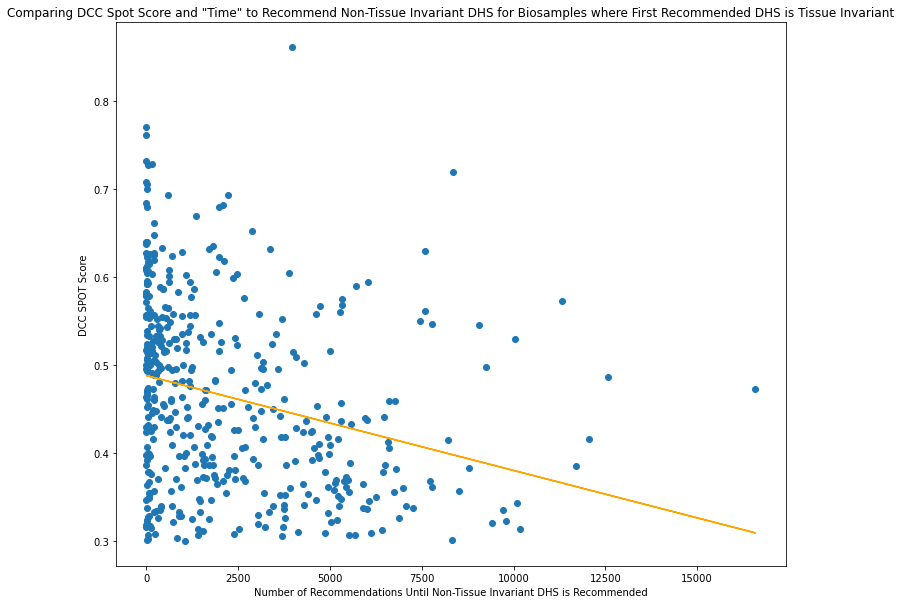

In [240]:
first_non_ti_all_np = np.array(first_non_ti_all)
spot_list_np = np.array(spot_list)

m, b, r_value, p_value, std_err = linregress(first_non_ti_all_np, spot_list_np)
print('r2 value =', r_value**2)

fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
plt.scatter(first_non_ti_all_np, spot_list_np)
plt.plot(first_non_ti_all_np, m*first_non_ti_all_np + b, color='orange')
plt.xlabel('Number of Recommendations Until Non-Tissue Invariant DHS is Recommended')
plt.ylabel('DCC SPOT Score')
plt.title('Comparing DCC Spot Score and "Time" to Recommend Non-Tissue Invariant DHS for Biosamples where First Recommended DHS is Tissue Invariant')

Text(0.5, 1.0, 'Comparing Prediction Scores within Recommendations for each Biosample where First Recommended DHS is Tissue Invariant')

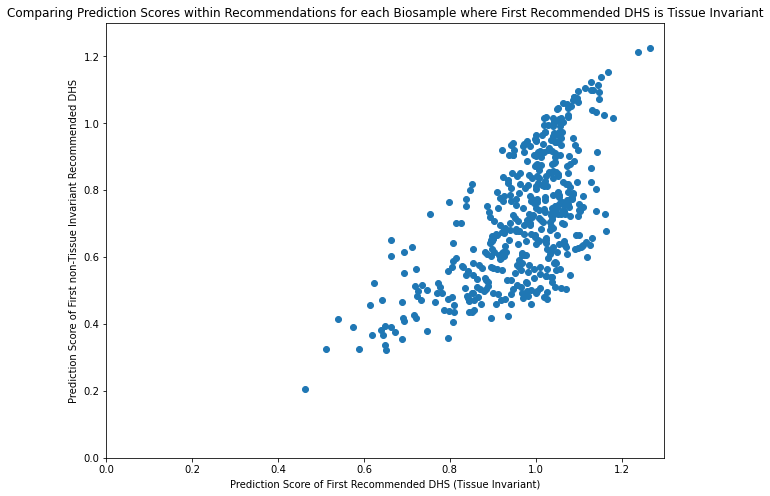

In [169]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')
plt.scatter(first_score, first_non_ti_score)
plt.xlim([0, 1.3])
plt.ylim([0, 1.3])
plt.xlabel('Prediction Score of First Recommended DHS (Tissue Invariant)')
plt.ylabel('Prediction Score of First non-Tissue Invariant Recommended DHS')
plt.title('Comparing Prediction Scores within Recommendations for each Biosample where First Recommended DHS is Tissue Invariant')

Text(0.5, 1.0, 'Prediction Scores for Top 20000 NMF Recommended DHSs for All Biosamples Where First Recommended DHS is Tissue Invariant')

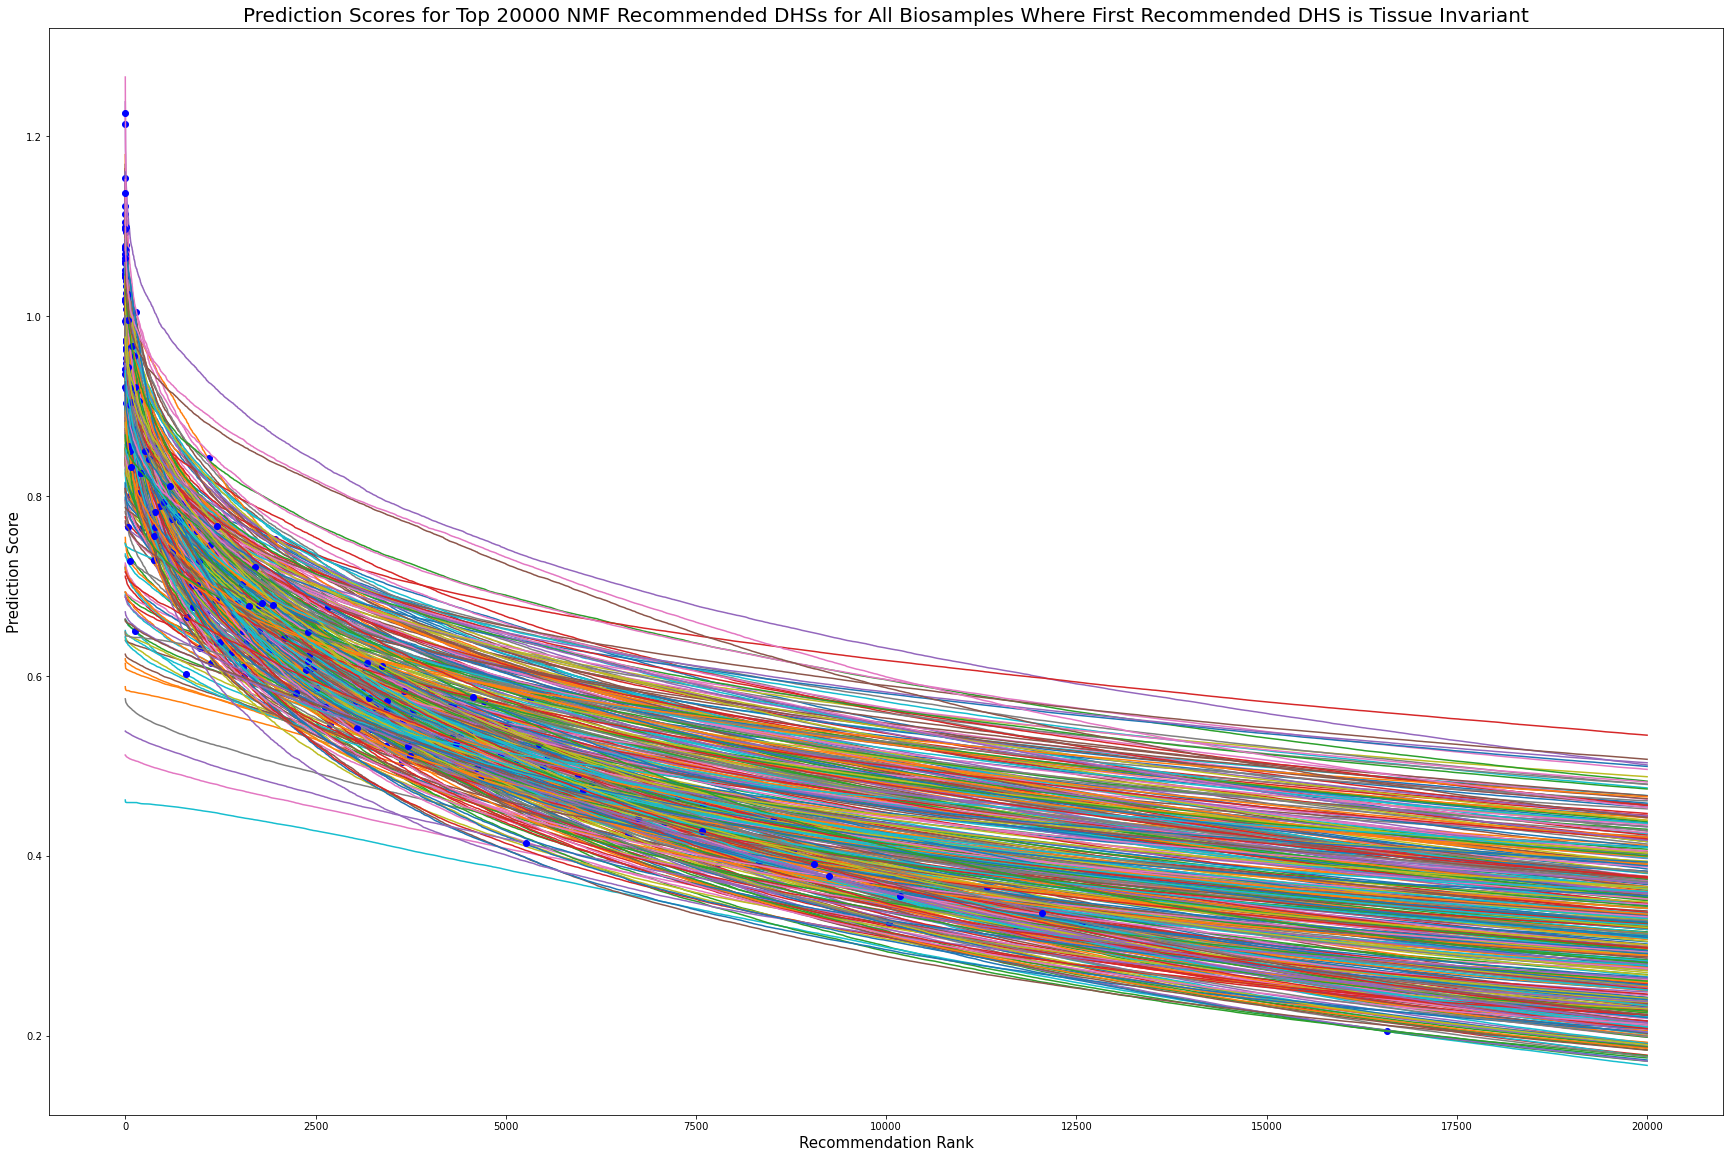

In [154]:
fig = plt.figure(figsize=(30, 20))
fig.patch.set_facecolor('white')
for biosample, i in zip(biosample_ind, range(len(biosample_ind))):
    plt.plot(range(len(rec_info_all[biosample][1][:20000])), rec_info_all[biosample][1][:20000])
    plt.plot(first_non_ti_all[i], rec_info_all[biosample][1][first_non_ti_all[i]], '-bo')
plt.xlabel('Recommendation Rank', fontsize=15)
plt.ylabel('Prediction Score', fontsize=15)
plt.title('Prediction Scores for Top 20000 NMF Recommended DHSs for All Biosamples Where First Recommended DHS is Tissue Invariant', fontsize=20)

Text(0.5, 1.0, 'Prediction Scores for Top 5000 NMF Recommended DHSs')

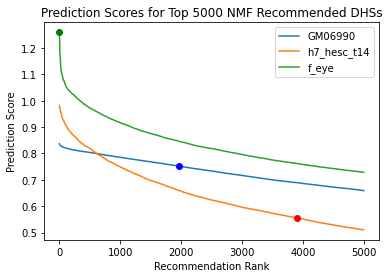

In [95]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(range(len(rec_info_GM06990[0][6][:5000])), rec_info_GM06990[0][6][:5000])
plt.plot(range(len(rec_info_h7_hesc_t14[0][6][:5000])), rec_info_h7_hesc_t14[0][6][:5000])
plt.plot(range(len(rec_info_f_eye[0][6][:5000])), rec_info_f_eye[0][6][:5000])

plt.plot(min(first_non_ti_GM06990), rec_info_GM06990[0][6][min(first_non_ti_GM06990)], '-bo')
plt.plot(min(first_non_ti_h7_hesc_t14), rec_info_h7_hesc_t14[0][6][min(first_non_ti_h7_hesc_t14)], '-ro')
plt.plot(min(first_non_ti_f_eye), rec_info_f_eye[0][6][min(first_non_ti_f_eye)], '-go')

plt.xlabel('Recommendation Rank')
plt.ylabel('Prediction Score')
plt.legend(['GM06990', 'h7_hesc_t14', 'f_eye'])
plt.title('Prediction Scores for Top 5000 NMF Recommended DHSs')

In [76]:
f= open('/home/ctrader/public_html/NMF_GM06990_recs_CT20211109.bed','w')
for i in range(100):
    f.write(rec_info_GM06990[0][1][i] + '\t' + str(rec_info_GM06990[0][2][i]) + '\t' + str(rec_info_GM06990[0][3][i]) + '\t' + rec_info_GM06990[0][0][i] + '\n')
f.close()

In [77]:
f= open('/home/ctrader/public_html/NMF_h7_hesc_t14_recs_CT20211109.bed','w')
for i in range(100):
    f.write(rec_info_h7_hesc_t14[0][1][i] + '\t' + str(rec_info_h7_hesc_t14[0][2][i]) + '\t' + str(rec_info_h7_hesc_t14[0][3][i]) + '\t' + rec_info_h7_hesc_t14[0][0][i] + '\n')
f.close()

In [78]:
f= open('/home/ctrader/public_html/NMF_f_eye_recs_CT20211109.bed','w')
for i in range(100):
    f.write(rec_info_f_eye[0][1][i] + '\t' + str(rec_info_f_eye[0][2][i]) + '\t' + str(rec_info_f_eye[0][3][i]) + '\t' + rec_info_f_eye[0][0][i] + '\n')
f.close()

In [ ]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [22]:
GM06990_all_comps_precision = []
GM06990_all_comps_recall = []
for comp in comps:
    k_vals = list(range(1, 500))
    k_vals.extend(list(np.arange(500, len(rec_info_GM06990[0][0]), 1000)))
#     print(k_vals[-1])
    comp_precision, comp_recall = component_precision_multiple_k(rec_info_GM06990[0], comp, k_vals)
    GM06990_all_comps_precision.append(comp_precision)
    GM06990_all_comps_recall.append(comp_recall)

In [27]:
h7_hesc_t14_all_comps_precision = []
h7_hesc_t14_all_comps_recall = []
for comp in comps:
    k_vals = list(range(1, 500))
    k_vals.extend(list(np.arange(500, len(rec_info_h7_hesc_t14[0][0]), 1000)))
#     print(k_vals[-1])
    comp_precision, comp_recall = component_precision_multiple_k(rec_info_h7_hesc_t14[0], comp, k_vals)
    h7_hesc_t14_all_comps_precision.append(comp_precision)
    h7_hesc_t14_all_comps_recall.append(comp_recall)

In [28]:
f_eye_all_comps_precision = []
f_eye_all_comps_recall = []
for comp in comps:
    k_vals = list(range(1, 500))
    k_vals.extend(list(np.arange(500, len(rec_info_f_eye[0][0]), 1000)))
#     print(k_vals[-1])
    comp_precision, comp_recall = component_precision_multiple_k(rec_info_f_eye[0], comp, k_vals)
    f_eye_all_comps_precision.append(comp_precision)
    f_eye_all_comps_recall.append(comp_recall)

In [98]:
rec_info_GM06990[0][0][-1005:-1001]

['Placental / trophoblast', 'Cardiac', 'Cardiac', 'Placental / trophoblast']

Text(0.5, 1.0, 'GM06990 (Lymphoid) Component PR Curves for NMF Recommendations')

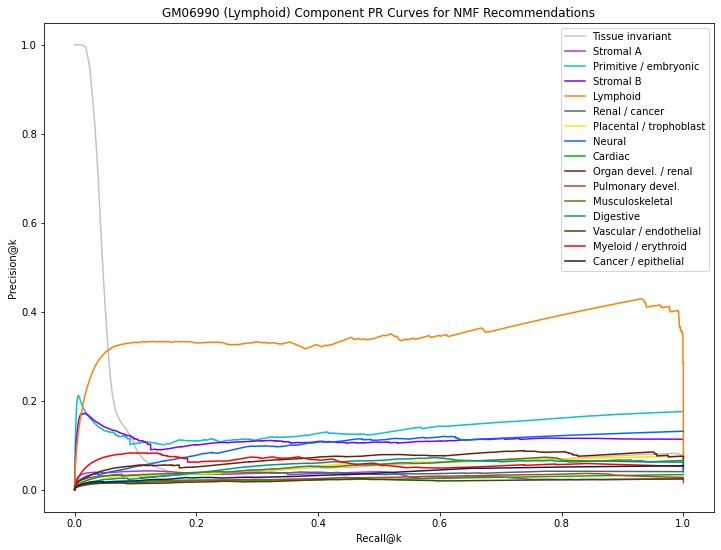

In [31]:
fig = plt.figure(figsize=(12,9)) #figsize=(15,10)
fig.patch.set_facecolor('white')
for i in range(len(comps)):
    plt.plot(GM06990_all_comps_recall[i], GM06990_all_comps_precision[i], color=color[i])
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.legend(comps)
plt.title('GM06990 (Lymphoid) Component PR Curves for NMF Recommendations')

Text(0.5, 1.0, 'H7_hESC_T14 (Cardiac) Component PR Curves for NMF Recommendations')

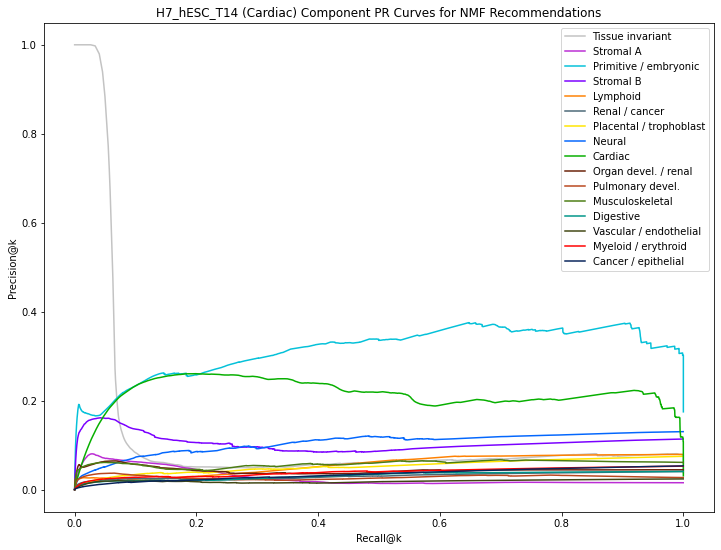

In [32]:
fig = plt.figure(figsize=(12,9))
fig.patch.set_facecolor('white')
for i in range(len(comps)):
    plt.plot(h7_hesc_t14_all_comps_recall[i], h7_hesc_t14_all_comps_precision[i], color=color[i])
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.legend(comps)
plt.title('H7_hESC_T14 (Cardiac) Component PR Curves for NMF Recommendations')

Text(0.5, 1.0, 'fEye (Neural) Component PR Curves for NMF Recommendations')

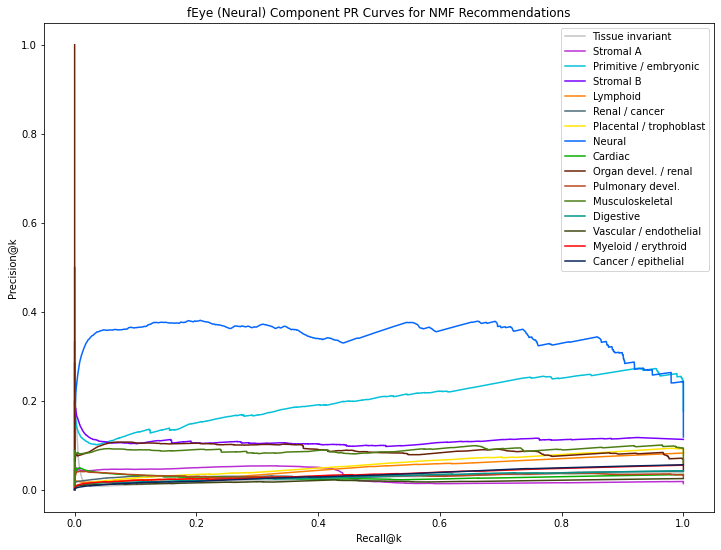

In [33]:
fig = plt.figure(figsize=(12,9))
fig.patch.set_facecolor('white')
for i in range(len(comps)):
    plt.plot(f_eye_all_comps_recall[i], f_eye_all_comps_precision[i], color=color[i])
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.legend(comps)
plt.title('fEye (Neural) Component PR Curves for NMF Recommendations')

**Unseen Pancreatic Cancer**

In [21]:
#Loading unseen pancreatic cancer biosample embeddings
fn = gzip.GzipFile('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/2021-11-16PancreaticCancerSpecialNC16seed20.npy.gz', "r")
unseen_pc_decomp_Basis = np.load(fn)

In [22]:
unseen_pc_decomp_Basis.shape

(747, 16)

In [23]:
#Fetch the new-to-be-added pancreatic cancer data, mapped to the 733-biosample Index
dat_pc = pd.read_table('/home/ctrader/vocab/Vocabulary/data/dat_pancreatic.txt.gz', header=None).T
dat_pc.shape

(14, 3591898)

In [24]:
#Combine the two datasets
dhs_pc = np.concatenate([dhs, dat_pc])
dhs_pc.shape

(747, 3591898)

In [27]:
# unseen_pc_rec_info = sample_recommendation(list(range(733, 747)), f_eye_signal, print_num=0, biosample_e=unseen_pc_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_pc, ROIurl=True, comps_to_filter_out=['Tissue invariant'])
unseen_pc_rec_info = sample_recommendation(list(range(733, 747)), f_eye_signal, print_num=0, biosample_e=unseen_pc_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_pc)

Biosample: LN51452 (733)
Biosample: LN51179 (734)
Biosample: LN51203 (735)
Biosample: LN51197 (736)
Biosample: LN51536 (737)
Biosample: LN51171 (738)
Biosample: LN51294 (739)
Biosample: LN51168 (740)
Biosample: LN51183 (741)
Biosample: LN51532 (742)
Biosample: LN51291 (743)
Biosample: LN51164 (744)
Biosample: LN51328 (745)
Biosample: LN51330 (746)


In [11]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [39]:
unseen_pc_biosample_precision = []
unseen_pc_biosample_recall = []
for sample in list(range(733, 747)):
    l = []
    l.append(sample)
    unseen_pc_rec_info_biosample = sample_recommendation(l, f_eye_signal, print_num=0, biosample_e=unseen_pc_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_pc)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(unseen_pc_rec_info_biosample[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    unseen_pc_biosample_precision.append(all_comps_precision)
    unseen_pc_biosample_recall.append(all_comps_recall)

Biosample: LN51452 (733)
Biosample: LN51179 (734)
Biosample: LN51203 (735)
Biosample: LN51197 (736)
Biosample: LN51536 (737)
Biosample: LN51171 (738)
Biosample: LN51294 (739)
Biosample: LN51168 (740)
Biosample: LN51183 (741)
Biosample: LN51532 (742)
Biosample: LN51291 (743)
Biosample: LN51164 (744)
Biosample: LN51328 (745)
Biosample: LN51330 (746)


In [45]:
#finding AUC values for each component of each unseen pancreatic cancer biosamples
total_unseen_pc_auc = []
for i in range(len(unseen_pc_biosample_precision)):
    comp_auc = []
    for j in range(len(unseen_pc_biosample_precision[i])):
        comp_auc.append(auc(unseen_pc_biosample_recall[i][j], unseen_pc_biosample_precision[i][j]))
    total_unseen_pc_auc.append(comp_auc)

In [70]:
#finding top AUC non-tissue invariant component for unseen pancreatic cancer biosamples
unseen_pc_top_comps = []
for biosample_auc in total_unseen_pc_auc:
    ind = biosample_auc.index(max(biosample_auc[1:]))
    unseen_pc_top_comps.append(comps[ind])

In [78]:
#filtering unseen rec info for only non-tissue invariant component with top AUC
top_comp_unseen_pc_rec_info = []
for i in range(len(unseen_pc_rec_info)):
    c = []
    c.append(unseen_pc_top_comps[i])
    top_comp_unseen_pc_rec_info.append(filter_in_recs(unseen_pc_rec_info[i], c))

In [94]:
for i in range(len(top_comp_unseen_pc_rec_info)):
    biosample = 733 + i
    biosample_name = pc_sample_names[i]
    print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
    link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_unseen_pc_rec_info[i])
    print(link_path)

Biosample: LN51452 (733)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_LN51452_733_filtered_recs_CT20211117.bed
Biosample: LN51179 (734)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_LN51179_734_filtered_recs_CT20211117.bed
Biosample: LN51203 (735)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_LN51203_735_filtered_recs_CT20211117.bed
Biosample: LN51197 (736)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_LN51197_736_filtered_recs_CT20211117.bed
Biosample: LN51536 (737)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_LN51536_737_filtered_recs_CT20211117.bed
Biosample: LN51171 (

In [26]:
f = open('/home/ctrader/vocab/Vocabulary/data/sampnams_pancreatic.txt', 'r')
pc_sample_names = f.read()
pc_sample_names = pc_sample_names.split('\n')
pc_sample_names = pc_sample_names[:14]
print(pc_sample_names)

['LN51452', 'LN51179', 'LN51203', 'LN51197', 'LN51536', 'LN51171', 'LN51294', 'LN51168', 'LN51183', 'LN51532', 'LN51291', 'LN51164', 'LN51328', 'LN51330']


Text(0.465, 1.03, 'Component PR Curve AUC Values for Unseen Pancreatic Cancer Biosamples with NMF Recommendations')

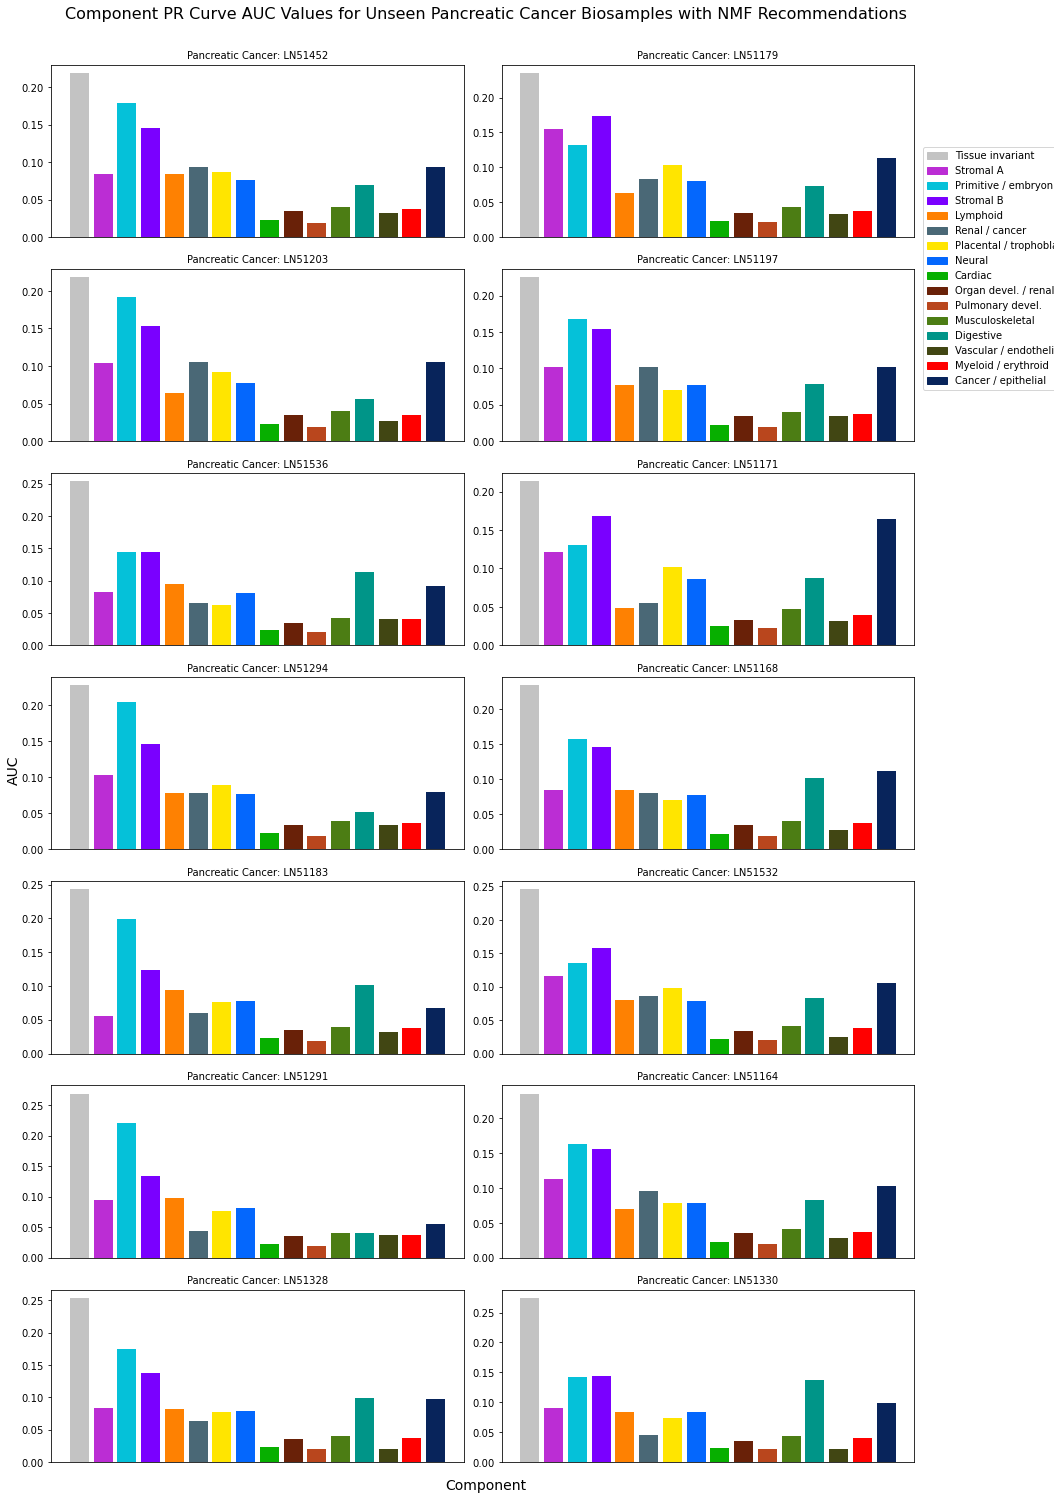

In [56]:
#plotting component PR curve AUC values
fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(14,20))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(14)):
    ax.bar(comps, total_unseen_pc_auc[ind], color=color)

    ax.set_title('Pancreatic Cancer: ' + pc_sample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Unseen Pancreatic Cancer Biosamples with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

Text(-0.01, 0.5, 'Precision@k')

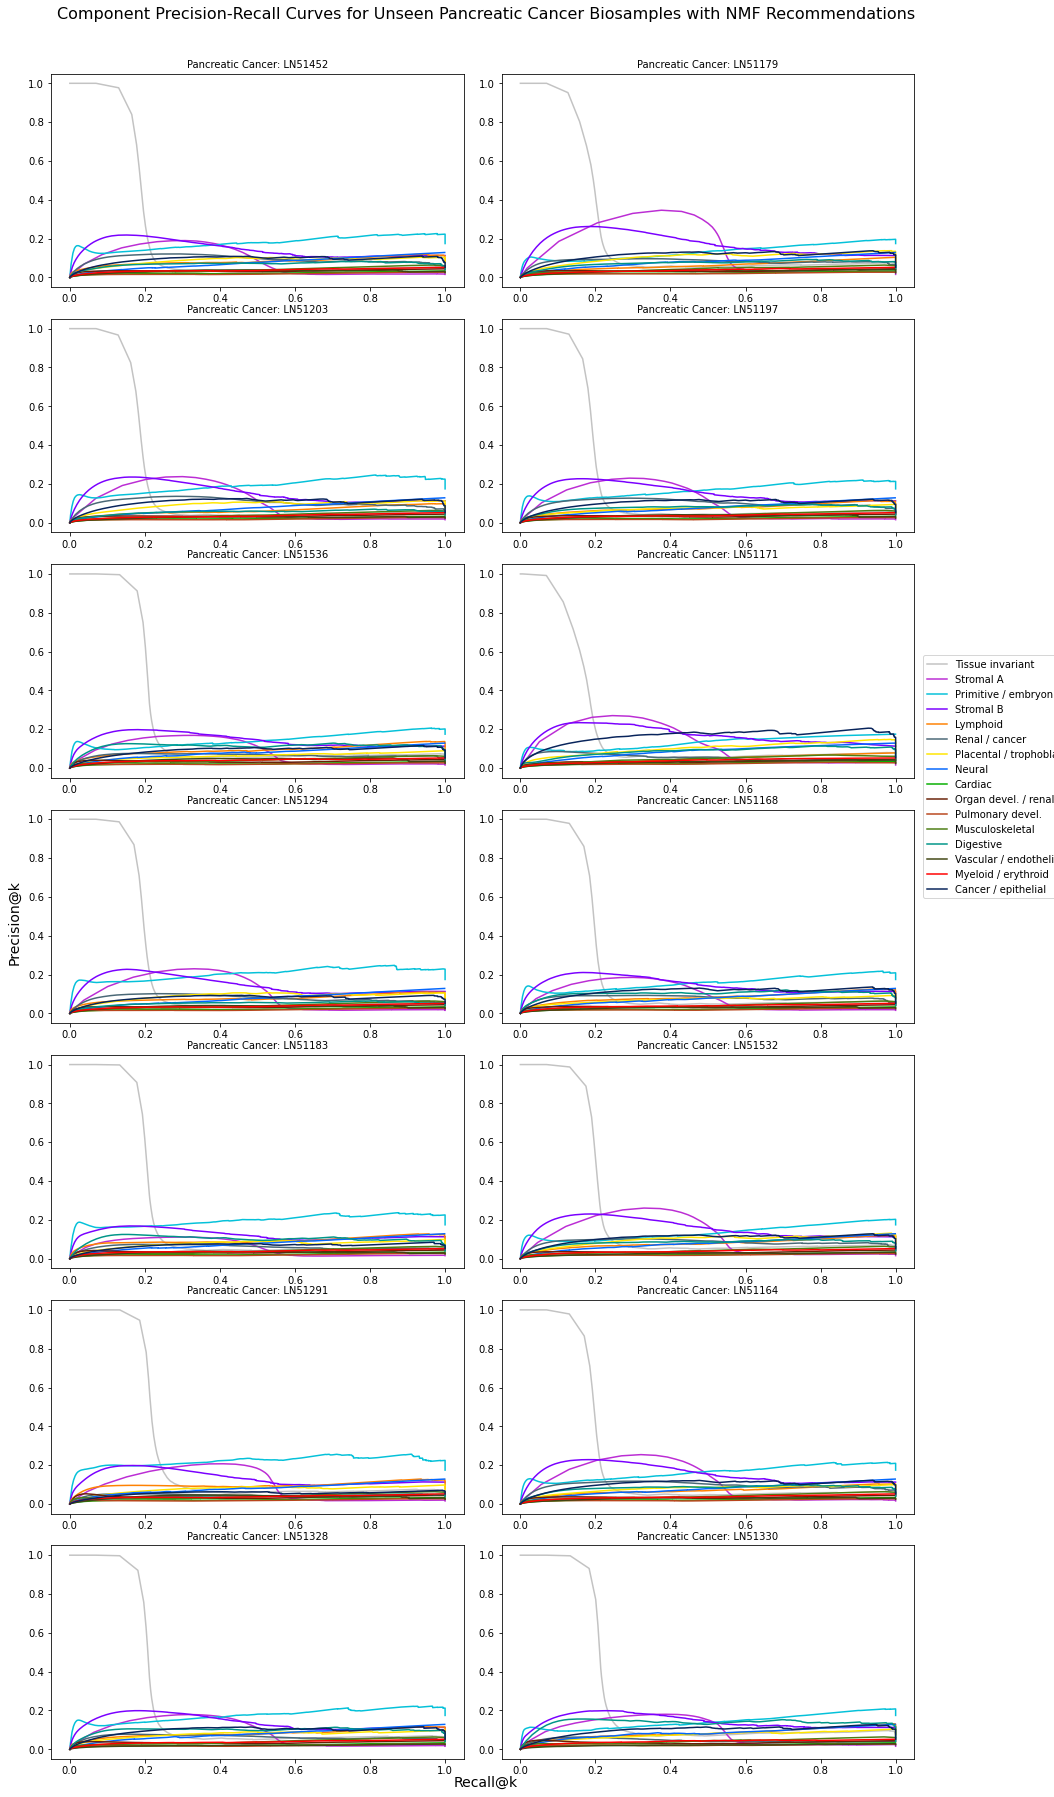

In [39]:
fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(14,24))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(14)):
    for i in range(len(comps)):
        ax.plot(unseen_pc_biosample_recall[ind][i], unseen_pc_biosample_precision[ind][i], color=color[i])
    ax.set_title('Pancreatic Cancer: ' + pc_sample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Unseen Pancreatic Cancer Biosamples with NMF Recommendations', fontsize=16, x=0.465, y=1.03)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

**Unseen Immune biosamples**

In [28]:
#Loading unseen immune biosample embeddings
fn = gzip.GzipFile('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/2020-04-14ImmuneSpecialNC16seed20.npy.gz', "r")
unseen_decomp_Basis = np.load(fn)

In [29]:
unseen_decomp_Basis.shape

(771, 16)

In [30]:
#Fetch the new-to-be-added immune data, mapped to the 733-biosample Index
dat_immune = pd.read_table('/home/ctrader/vocab/Vocabulary/data/dat_immunopedia.txt.gz', header=None).T
dat_immune.shape

(38, 3591898)

In [31]:
#Combine the two datasets
dhs_immune = np.concatenate([dhs, dat_immune])
dhs_immune.shape

(771, 3591898)

In [33]:
# unseen_rec_info = sample_recommendation(list(range(733, 771)), f_eye_signal, print_num=0, biosample_e=unseen_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_immune, ROIurl=True, comps_to_filter_out=['Tissue invariant'])
unseen_rec_info = sample_recommendation(list(range(733, 771)), f_eye_signal, print_num=0, biosample_e=unseen_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_immune)

Biosample: h.CD4.Th17 (733)
Biosample: h.CD8.memory.effector (734)
Biosample: h.CD4.Treg (735)
Biosample: h.CD4+ (736)
Biosample: h.CD4+ (737)
Biosample: h.CD4+ (738)
Biosample: h.CD4.effector (739)
Biosample: h.CD4.Treg (740)
Biosample: h.CD4.Th1 (741)
Biosample: h.CD4+ (742)
Biosample: h.CD8+ (743)
Biosample: h.CD8+ (744)
Biosample: h.CD8+ (745)
Biosample: h.CD4+ (746)
Biosample: h.CD3+ (747)
Biosample: h.CD4+ (748)
Biosample: h.CD8+ (749)
Biosample: h.CD8+ (750)
Biosample: h.CD3+ (751)
Biosample: h.CD4.Th17 (752)
Biosample: h.CD4.memory.effector (753)
Biosample: h.CD4.naive (754)
Biosample: h.CD4.Th9 (755)
Biosample: h.CD4.Th22 (756)
Biosample: h.CD4.Tfh (757)
Biosample: h.CD4.memory.effector (758)
Biosample: h.CD4.naive (759)
Biosample: h.CD8.naive (760)
Biosample: h.CD4.Th1 (761)
Biosample: h.CD4.Th17 (762)
Biosample: h.CD8.naive (763)
Biosample: h.CD4.Th2 (764)
Biosample: h.CD8.naive (765)
Biosample: h.CD4.Th2 (766)
Biosample: h.CD4.memory.effector (767)
Biosample: h.CD4.Th1 (768

In [54]:
#Immune component preceision and recall
unseen_biosample_precision = []
unseen_biosample_recall = []
for sample in list(range(733, 771)):
    l = []
    l.append(sample)
    unseen_rec_info_biosample = sample_recommendation(l, f_eye_signal, print_num=0, biosample_e=unseen_decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs_immune)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(unseen_rec_info_biosample[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    unseen_biosample_precision.append(all_comps_precision)
    unseen_biosample_recall.append(all_comps_recall)

Biosample: h.CD4.Th17 (733)
Biosample: h.CD8.memory.effector (734)
Biosample: h.CD4.Treg (735)
Biosample: h.CD4+ (736)
Biosample: h.CD4+ (737)
Biosample: h.CD4+ (738)
Biosample: h.CD4.effector (739)
Biosample: h.CD4.Treg (740)
Biosample: h.CD4.Th1 (741)
Biosample: h.CD4+ (742)
Biosample: h.CD8+ (743)
Biosample: h.CD8+ (744)
Biosample: h.CD8+ (745)
Biosample: h.CD4+ (746)
Biosample: h.CD3+ (747)
Biosample: h.CD4+ (748)
Biosample: h.CD8+ (749)
Biosample: h.CD8+ (750)
Biosample: h.CD3+ (751)
Biosample: h.CD4.Th17 (752)
Biosample: h.CD4.memory.effector (753)
Biosample: h.CD4.naive (754)
Biosample: h.CD4.Th9 (755)
Biosample: h.CD4.Th22 (756)
Biosample: h.CD4.Tfh (757)
Biosample: h.CD4.memory.effector (758)
Biosample: h.CD4.naive (759)
Biosample: h.CD8.naive (760)
Biosample: h.CD4.Th1 (761)
Biosample: h.CD4.Th17 (762)
Biosample: h.CD8.naive (763)
Biosample: h.CD4.Th2 (764)
Biosample: h.CD8.naive (765)
Biosample: h.CD4.Th2 (766)
Biosample: h.CD4.memory.effector (767)
Biosample: h.CD4.Th1 (768

In [55]:
#finding AUC values for each component of each unseen immune biosample
total_unseen_immune_auc = []
for i in range(len(unseen_biosample_precision)):
    comp_auc = []
    for j in range(len(unseen_biosample_precision[i])):
        comp_auc.append(auc(unseen_biosample_recall[i][j], unseen_biosample_precision[i][j]))
    total_unseen_immune_auc.append(comp_auc)

In [83]:
#finding top AUC non-tissue invariant component for unseen immune biosamples
unseen_immune_top_comps = []
for biosample_auc in total_unseen_immune_auc:
    ind = biosample_auc.index(max(biosample_auc[1:]))
    unseen_immune_top_comps.append(comps[ind])

In [85]:
#filtering unseen immune rec info for only non-tissue invariant component with top AUC
top_comp_unseen_immune_rec_info = []
for i in range(len(unseen_rec_info)):
    c = []
    c.append(unseen_immune_top_comps[i])
    top_comp_unseen_immune_rec_info.append(filter_in_recs(unseen_rec_info[i], c))

In [95]:
for i in range(len(top_comp_unseen_immune_rec_info)):
    biosample = 733 + i
    biosample_name = immune_sample_names[i]
    print('Biosample: ' + biosample_name + ' (' + str(biosample) + ')')
    link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', top_comp_unseen_immune_rec_info[i])
    print(link_path)

Biosample: h.CD4.Th17 (733)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h.CD4.Th17_733_filtered_recs_CT20211117.bed
Biosample: h.CD8.memory.effector (734)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h.CD8.memory.effector_734_filtered_recs_CT20211117.bed
Biosample: h.CD4.Treg (735)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h.CD4.Treg_735_filtered_recs_CT20211117.bed
Biosample: h.CD4+ (736)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h.CD4+_736_filtered_recs_CT20211117.bed
Biosample: h.CD4+ (737)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_h.CD4+_737_filtered_recs

In [16]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [58]:
f = open('/home/ctrader/vocab/Vocabulary/data/sampnams_immunopedia.txt', 'r')
immune_sample_names = f.read()
immune_sample_names = immune_sample_names.split('\n')
immune_sample_names = immune_sample_names[:38]
print(immune_sample_names)

['h.CD4.Th17', 'h.CD8.memory.effector', 'h.CD4.Treg', 'h.CD4+', 'h.CD4+', 'h.CD4+', 'h.CD4.effector', 'h.CD4.Treg', 'h.CD4.Th1', 'h.CD4+', 'h.CD8+', 'h.CD8+', 'h.CD8+', 'h.CD4+', 'h.CD3+', 'h.CD4+', 'h.CD8+', 'h.CD8+', 'h.CD3+', 'h.CD4.Th17', 'h.CD4.memory.effector', 'h.CD4.naive', 'h.CD4.Th9', 'h.CD4.Th22', 'h.CD4.Tfh', 'h.CD4.memory.effector', 'h.CD4.naive', 'h.CD8.naive', 'h.CD4.Th1', 'h.CD4.Th17', 'h.CD8.naive', 'h.CD4.Th2', 'h.CD8.naive', 'h.CD4.Th2', 'h.CD4.memory.effector', 'h.CD4.Th1', 'h.CD8.memory.effector', 'h.CD4.effector']


Text(0.465, 1.03, 'Component PR Curve AUC Values for Unseen Immune Biosamples with NMF Recommendations')

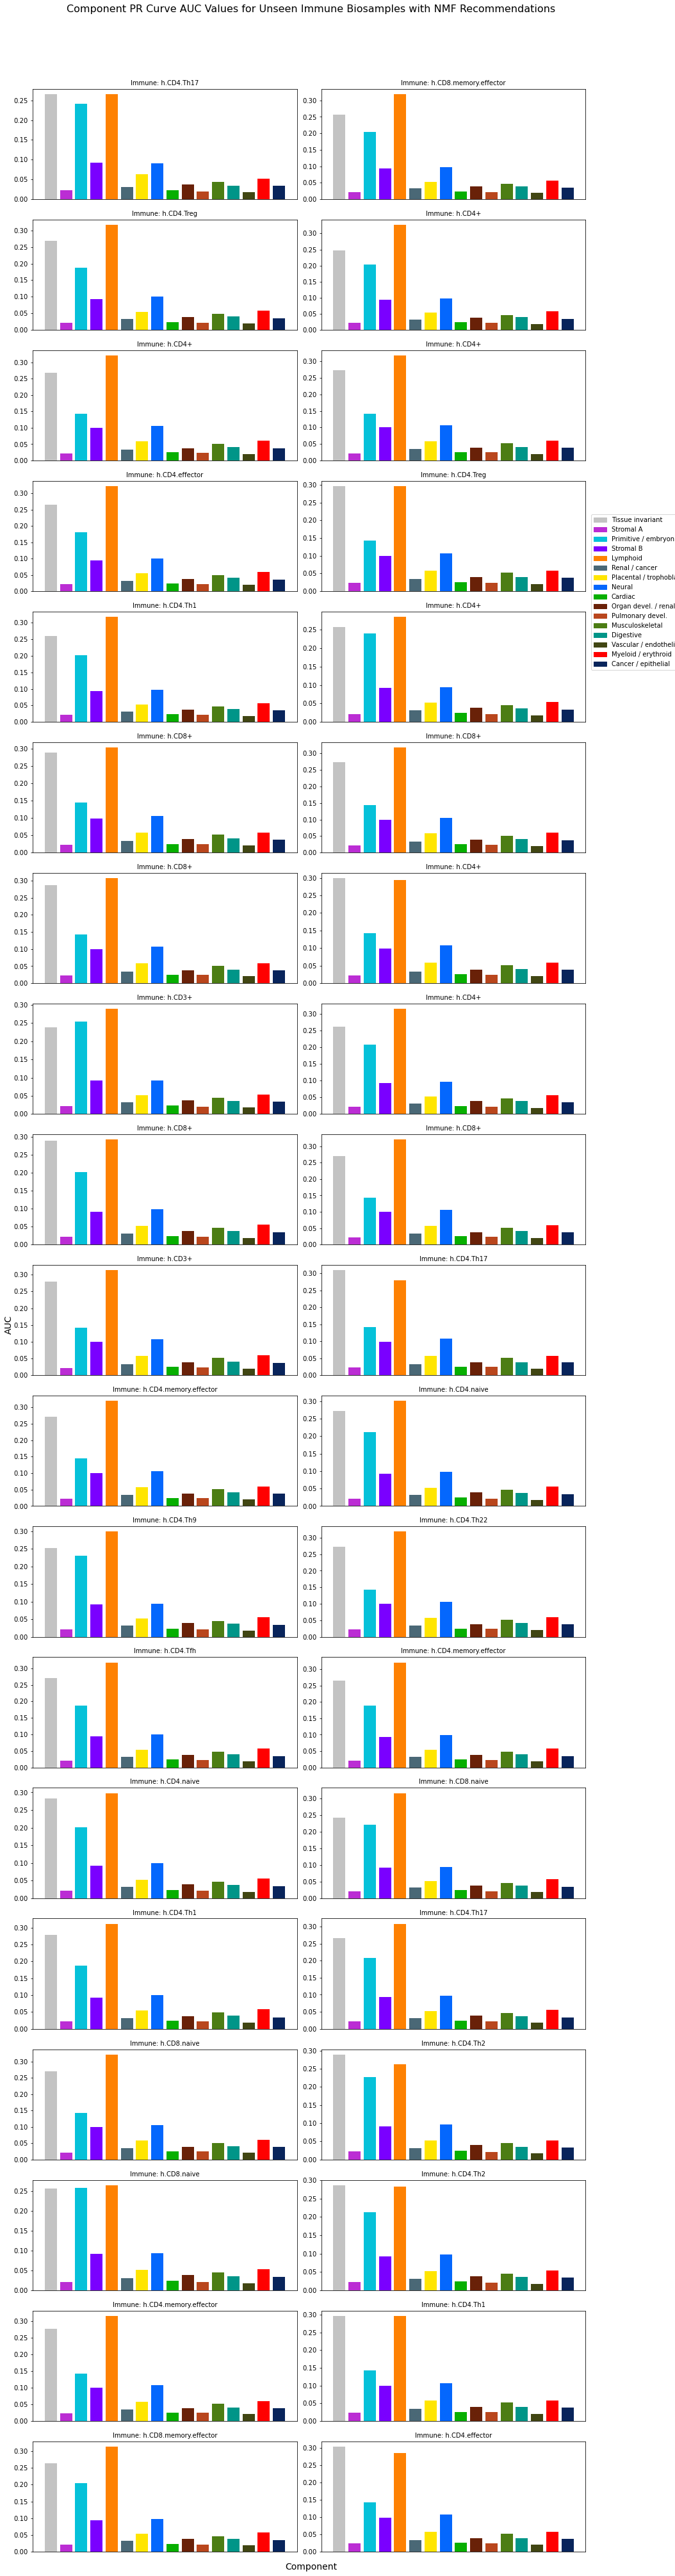

In [59]:
#plotting component PR curve AUC values
fig, axes = plt.subplots(nrows=19, ncols=2, figsize=(14,54))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(38)):
    ax.bar(comps, total_unseen_immune_auc[ind], color=color)

    ax.set_title('Immune: ' + immune_sample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Unseen Immune Biosamples with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

Text(-0.01, 0.5, 'Precision@k')

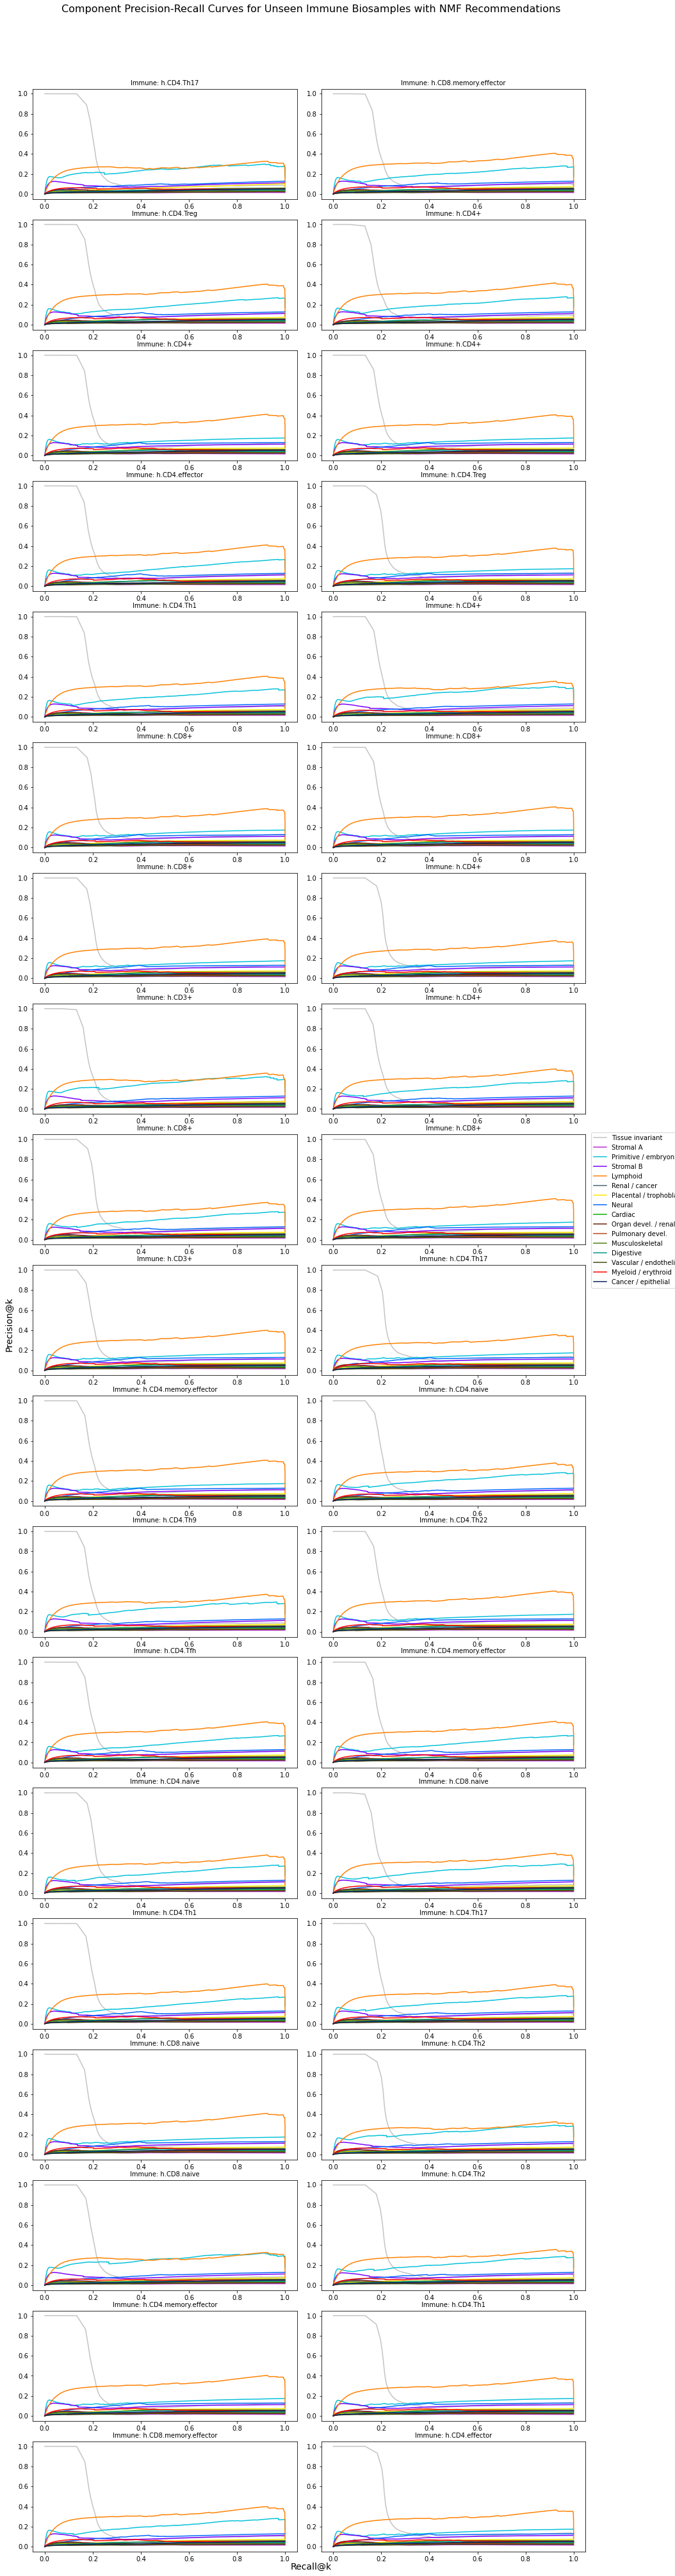

In [51]:
fig, axes = plt.subplots(nrows=19, ncols=2, figsize=(14,54))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(38)):
    for i in range(len(comps)):
        ax.plot(unseen_biosample_recall[ind][i], unseen_biosample_precision[ind][i], color=color[i])
    ax.set_title('Immune: ' + immune_sample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Unseen Immune Biosamples with NMF Recommendations', fontsize=16, x=0.465, y=1.03)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

**Functions**

In [14]:
#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision_multiple_k(rec_info, target_comp, k_vals):
    comps = np.array(rec_info[0])
#     print(comps)
    comps_np = np.where(comps == target_comp, 1, 0)
#     print(comps_np)
    total_of_comp = np.sum(comps_np)
#     print(total_of_comp)
    count_list = []
    for k in k_vals:
        comp_k = comps_np[:k]
        count = np.sum(comp_k)
        count_list.append(count)
    counts = np.array(count_list)
    precision = counts/k_vals
    recall = counts/total_of_comp
    return precision, recall

In [15]:
#creates ROIurl links for recommended DHSs
def make_roi_url(biosample_name, biosample, rec_info):
    today = date.today()
    bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(100):
        f.write(rec_info[1][i] + '\t' + str(rec_info[2][i]) + '\t' + str(rec_info[3][i]) + '\t' + rec_info[0][i] + '\n')
    f.close()
    link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed'
    return link_path

In [16]:
def filter_in_recs(rec_info, comps_to_filter_in):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_in:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    leftover_ind = np.array(filter_inds)
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_in_recs(unseen_pc_rec_info[0], ['Tissue invariant'])

In [17]:
def filter_out_recs(rec_info, comps_to_filter_out):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_out:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    filter_inds = set(filter_inds)
    leftover_ind = np.array(list(set(range(len(rec_comps))) - filter_inds))
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_recs(unseen_rec_info[0], ['Tissue invariant'])

In [13]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(biosamples, signal_data, print_num=3, biosample_e=decomp_Basis, DHS_e=decomp_Mixture, dhs=dhs, ROIurl=False, comps_to_filter_out=[]): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_biosample_e = biosample_e.shape
    n_DHS_e, n_DHSs = DHS_e.shape
    return_list = []
    metadata = DHS_metadata.reset_index()
    comp_ser = metadata['component']
    chrom_ser = metadata['seqname']
    start_ser = metadata['start']
    end_ser = metadata['end']
    numsamples_ser = metadata['numsamples']
    identifier_ser = metadata['identifier']
    
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
            
        else:
            biosample = biosample_name
            if (biosample > 732) & (n_biosamples == 747): #Pancreatic Cancer data
                relative_num = biosample - 733
                biosample_name = pc_sample_names[relative_num]
            elif (biosample > 732) & (n_biosamples == 771): #Immune data
                relative_num = biosample - 733
                biosample_name = immune_sample_names[relative_num]
            else:
                biosample_name = list(biosample_df[biosample_df['library order']==biosample+1]['Biosample name'])[0]
            
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predictions that relate to biosample
        filtered_scores = np.dot(biosample_e[biosample, :], DHS_e[:, np.array(not_known_ind)])
        

        #rank from most related to least
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        top_filtered_scores = filtered_scores[filtered_top_DHSs]
        
        comp_rec = list(comp_ser[top_rec_DHSs])
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_rec = list(start_ser[top_rec_DHSs])
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        identifier_rec = list(identifier_ser[top_rec_DHSs])
        
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_biosample.append(list(top_filtered_scores))
        
        if comps_to_filter_out:
            return_biosample = filter_out_recs(return_biosample, comps_to_filter_out)
        
        return_list.append(return_biosample)
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        
        if ROIurl == True:
            #creating ROIurl link
            if comps_to_filter:
                link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', return_biosample)
            else:
                link_path = make_roi_url(biosample_name, biosample, return_biosample)
            print(link_path)
        
        if print_num > 0:
            print('   Number of Known DHSs: %s' %(len(known_positives)))
            print()
            print('   Recommended DHS Locations: ') 
            print('   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal')
        
        
        
            dhs_ids = top_rec_DHSs.to_numpy()
            #dhs to the right of recommended dhs
            dhs_right = dhs_ids[:]+1
            #dhs to the left of recommended dhs
            dhs_left = dhs_ids[:]-1
        
            #removing dhss that are "neighbored" across chromosomes
            chrm_list = list(np.unique(list(DHS_metadata['seqname'])))
            rows_per_chrm = [0]
            for chrm in chrm_list:
                max_row = max(rows_per_chrm)
                rows, col = DHS_metadata[DHS_metadata['seqname']==chrm].shape
                rows_per_chrm.append(rows + max_row)
            rows_per_chrm = np.array(rows_per_chrm)
        
            dhs_right = np.delete(dhs_right, np.isin(dhs_right, rows_per_chrm))
            dhs_left = np.delete(dhs_left, np.isin(dhs_left, rows_per_chrm-1))
        
            #determining presence/absense of dhss to right and left of recommended dhs
            right = dhs_array[biosample, dhs_right] 
            left = dhs_array[biosample, dhs_left]
        
            #signal data
            sample_rec_dhs_signal, rec_dhs_signal, rec_identifier = signal_values(list(top_rec_DHSs), signal_data)
            sample_right_dhs_signal, right_dhs_signal, right_identifier = signal_values(list(dhs_right), signal_data)
            sample_left_dhs_signal, left_dhs_signal, left_identifier = signal_values(list(dhs_left), signal_data)
#         print(rec_identifier[:5])
#         print(identifier_rec[:5])
        
        
            for i in range(print_num):
#             print(identifier_rec[i])
#             print(rec_identifier[:5])
#             print(list(rec_identifier)[i])
                chrom = chrom_rec[i]
                start = start_rec[i]
                end = end_rec[i]
                component = comp_rec[i]
                num_samples = numsamples_rec[i]
                sample_rec_dhs_signal_i = round(list(sample_rec_dhs_signal)[i], 3)
                rec_dhs_signal_i = round(float(list(rec_dhs_signal)[i]), 3)
                dhs_id = list(top_rec_DHSs)[i]
                right_id = list(np.where(dhs_right == dhs_id+1))[0] #+1
                if list(right_id) and right[right_id]==1:
#                 print(int(right_id[0]))
                    sample_right_dhs_signal_i = round(sample_right_dhs_signal[int(right_id[0])], 3)
                    right_dhs_signal_i = round(right_dhs_signal[int(right_id[0])], 3)
                    right_print = str(round(sample_right_dhs_signal_i, 3)) + '/' + str(round(right_dhs_signal_i, 3))
                else:
                    right_print = 'N/A'
            
                left_id = list(np.where(dhs_left == dhs_id-1))[0]
                if list(left_id) and left[left_id]==1:
#                 print(int(left_id[0]))
                    sample_left_dhs_signal_i = round(sample_left_dhs_signal[int(left_id[0])], 3)
                    left_dhs_signal_i = round(left_dhs_signal[int(left_id[0])], 3)
                    left_print = str(round(sample_left_dhs_signal_i, 3)) + '/' + str(round(left_dhs_signal_i, 3))
                else:
                    left_print = 'N/A'
                
                
                print('      %s:%s-%s | %s | %s | %s/%s | %s | %s'
                      %(chrom, start, end, component, num_samples, sample_rec_dhs_signal_i, rec_dhs_signal_i,
                       left_print, right_print))

    return return_list

In [12]:
#Takes in recommended DHS indices and the signal data from a single biosample. Returns the average biosample signal
#across each recommended DHS and the average signal of all biosamples at each recommended DHS. 
def signal_values(dhs, signal_data):
    identifier_series = pd.Series(signal_data['name'])
    identifier = identifier_series[dhs]
    #Average biosample signal across each recommended DHS
    mean_signal_sample_series = pd.Series(signal_data['mean'])
    mean_signal_sample = mean_signal_sample_series[dhs]
    #Average signal of all biosamples at each recommended DHS
    mean_signal_DHS_series = pd.Series(DHS_metadata['mean_signal'])
    mean_signal_DHS = mean_signal_DHS_series[dhs]
    return list(mean_signal_sample), list(mean_signal_DHS), list(identifier)

In [18]:
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

733 3591898


In [19]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [52]:
#Calculating precision and recall for already seen data
ordered_list = []
row_count_list = np.sum(dhs_array, axis=1)
scores = np.dot(decomp_Basis, decomp_Mixture)
for row in range(n_biosamples):
    #ordering scores
    ordered = np.argsort(-scores[row])
    #ordering DHS values that were not known positives in train set
    ordered_row_data = dhs_array[row, ordered]
    ordered_list.append(ordered_row_data)
precision = []
recall = []
for k in k_vals:
    k_precision = []
    k_recall = []
    for row in range(n_biosamples):
        #for each biosample, calculates precision for the top k DHS recs
        count = np.sum(ordered_list[row][:k])
        k_precision.append(count/k) #this is how lightFM calculates precision
        k_recall.append(count/row_count_list[row])
    precision.append(k_precision)
    recall.append(k_recall)

In [53]:
#Calculating precision and recall for unseen immune data
unseen_biosamples = list(range(733, 771))
ordered_list = []
row_count_list = np.sum(dhs_immune, axis=1)
scores = np.dot(unseen_decomp_Basis, decomp_Mixture)
for row in unseen_biosamples:
    #ordering scores
    ordered = np.argsort(-scores[row])
    #ordering DHS values that were not known positives in train set
    ordered_row_data = dhs_immune[row, ordered]
    ordered_list.append(ordered_row_data)
unseen_precision = []
unseen_recall = []
for k in k_vals:
    k_precision = []
    k_recall = []
    for row, i in zip(unseen_biosamples, list(range(771-733))):
        #for each biosample, calculates precision for the top k DHS recs
        count = np.sum(ordered_list[i][:k])
        k_precision.append(count/k) #this is how lightFM calculates precision
        k_recall.append(count/row_count_list[row])
    unseen_precision.append(k_precision)
    unseen_recall.append(k_recall)

In [54]:
#Calculating precision and recall for unseen immune data
unseen_pc_biosamples = list(range(733, 747))
ordered_list = []
row_count_list = np.sum(dhs_pc, axis=1)
scores = np.dot(unseen_pc_decomp_Basis, decomp_Mixture)
for row in unseen_pc_biosamples:
    #ordering scores
    ordered = np.argsort(-scores[row])
    #ordering DHS values that were not known positives in train set
    ordered_row_data = dhs_pc[row, ordered]
    ordered_list.append(ordered_row_data)
unseen_pc_precision = []
unseen_pc_recall = []
for k in k_vals:
    k_precision = []
    k_recall = []
    for row, i in zip(unseen_pc_biosamples, list(range(747-733))):
        #for each biosample, calculates precision for the top k DHS recs
        count = np.sum(ordered_list[i][:k])
        k_precision.append(count/k) #this is how lightFM calculates precision
        k_recall.append(count/row_count_list[row])
    unseen_pc_precision.append(k_precision)
    unseen_pc_recall.append(k_recall)

In [55]:
unseen_pc_precision_mean = []
for i in range(len(unseen_pc_precision)):
    unseen_pc_precision_mean.append(np.mean(unseen_pc_precision[i]))
unseen_pc_recall_mean = []
for i in range(len(unseen_pc_recall)):
    unseen_pc_recall_mean.append(np.mean(unseen_pc_recall[i]))

In [56]:
unseen_precision_mean = []
for i in range(len(unseen_precision)):
    unseen_precision_mean.append(np.mean(unseen_precision[i]))
unseen_recall_mean = []
for i in range(len(unseen_recall)):
    unseen_recall_mean.append(np.mean(unseen_recall[i]))

In [57]:
precision_mean = []
for i in range(len(precision)):
    precision_mean.append(np.mean(precision[i]))
recall_mean = []
for i in range(len(recall)):
    recall_mean.append(np.mean(recall[i]))

Text(0.5, 1.0, 'Precision-Recall Curves for Recommendations Generated from NMF Embeddings')

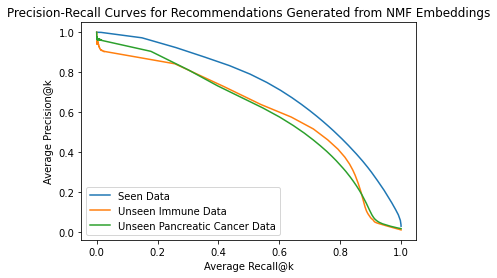

In [58]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.plot(recall_mean, precision_mean)
plt.plot(unseen_recall_mean, unseen_precision_mean)
plt.plot(unseen_pc_recall_mean, unseen_pc_precision_mean)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Seen Data', 'Unseen Immune Data', 'Unseen Pancreatic Cancer Data'])
plt.title('Precision-Recall Curves for Recommendations Generated from NMF Embeddings')

In [133]:
#Finding range of recommendation scores
scores = np.dot(decomp_Basis, decomp_Mixture)
row_max = np.max(scores, axis=1)
row_min = np.min(scores, axis=1)
print(min(row_min))
print(max(row_max))

0.0
2.357513215320604


In [19]:
#Top 15 biosamples of each component
top_biosamples = pd.read_table('/home/ctrader/lightfm_data/top15NMFBasisLoadings.txt')

In [20]:
# comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
# color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
biosamples = []
biosample_names = []
for comp in comps:
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]]['Biosample name'])[0])
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]]['Biosample name'])[0])

In [21]:
top_biosample_precision = []
top_biosample_recall = []
for sample in biosamples:
    l = []
    l.append(sample)
    rec_info = sample_recommendation(l, GM06990_signal, print_num=0)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    top_biosample_precision.append(all_comps_precision)
    top_biosample_recall.append(all_comps_recall)

Biosample: 262 (262)
   Number of Known DHSs: 45431

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 227 (227)
   Number of Known DHSs: 47071

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 444 (444)
   Number of Known DHSs: 100575

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 125 (125)
   Number of Known DHSs: 89913

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal
Biosample: 44 (44)
   Number of Known DHSs: 314868

   Recommended DHS Locations: 
   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Si

In [ ]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_precision.pickle', 'wb')
pickle.dump(top_biosample_precision, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_recall.pickle', 'wb')
pickle.dump(top_biosample_recall, pickle_out)
pickle_out.close()

In [17]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_precision.pickle', 'rb')
top_biosample_precision=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_top1_top15_biosamples_each_comp_recall.pickle', 'rb')
top_biosample_recall=pickle.load(pickle_in)

Text(0, 0.5, 'Precision@k')

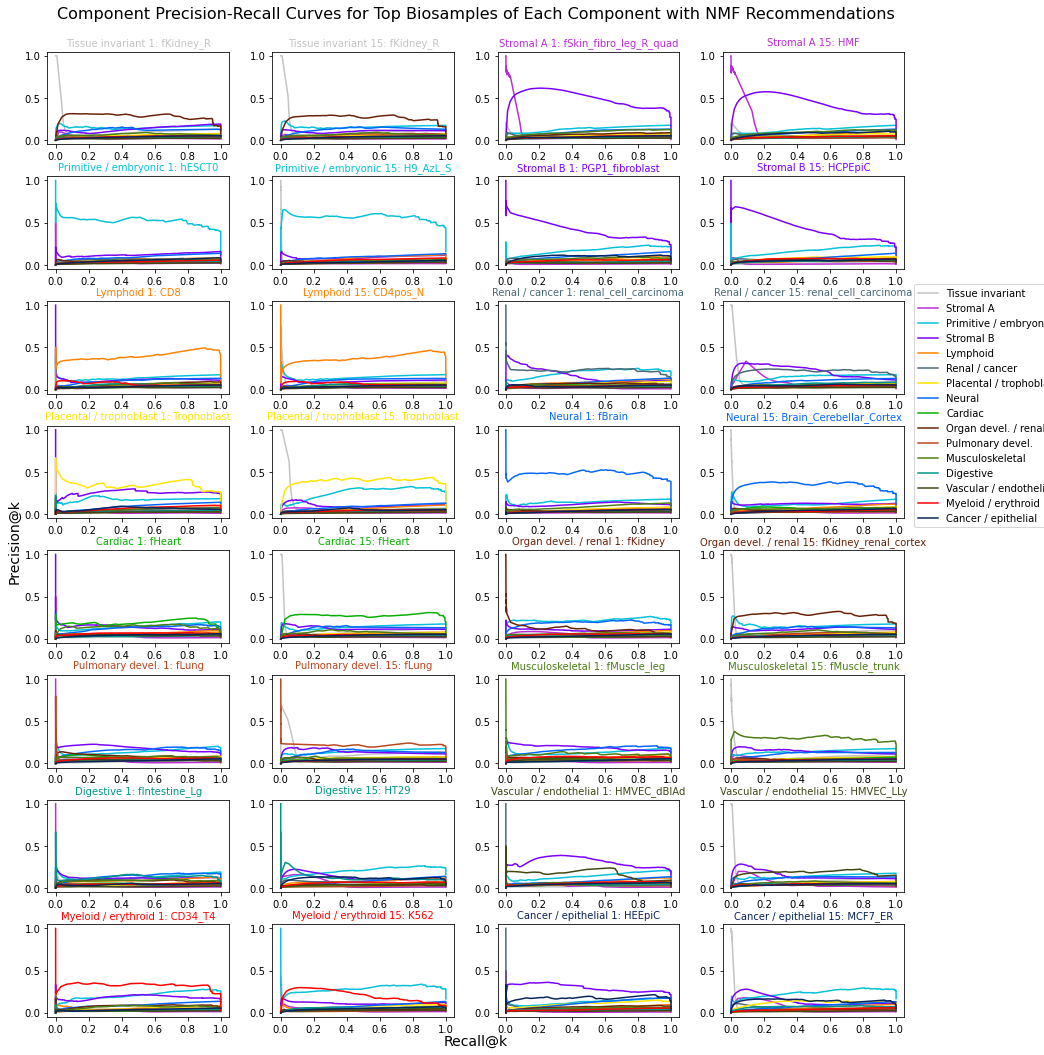

In [21]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
    for i in range(len(comps)):
        ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    if ind % 2 == 0:
        biosample_rank = '1'
    else:
        biosample_rank = '15'
    component = comps[ind // 2]
    ax.set_title(component + ' ' + biosample_rank + ': ' + biosample_names[ind], fontsize=10, color=color[ind//2])


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Top Biosamples of Each Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(0, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

In [22]:
#to plot component PR curve AUC values
total_auc = []
for i in range(len(top_biosample_precision)):
    comp_auc = []
    for j in range(len(top_biosample_precision[i])):
        comp_auc.append(auc(top_biosample_recall[i][j], top_biosample_precision[i][j]))
    total_auc.append(comp_auc)

Text(0.465, 1.03, 'Component PR Curve AUC Values for Top Biosamples of Each Component with NMF Recommendations')

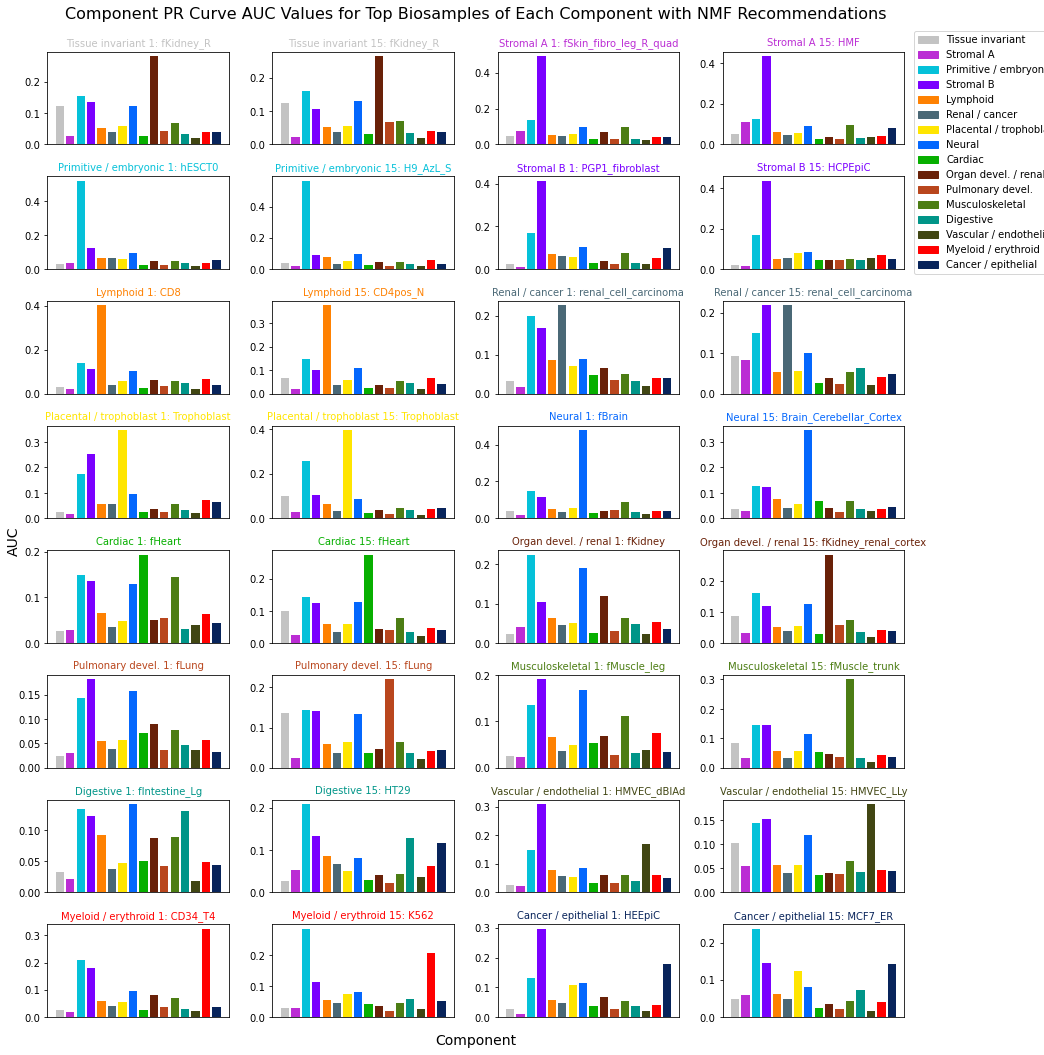

In [23]:
#plotting component PR curve AUC values
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
#     for i in range(len(comps)):
#         ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    ax.bar(comps, total_auc[ind], color=color)
    if ind % 2 == 0:
        biosample_rank = '1'
    else:
        biosample_rank = '15'
    component = comps[ind // 2]
    ax.set_title(component + ' ' + biosample_rank + ': ' + biosample_names[ind], fontsize=10, color=color[ind//2])
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(0, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Top Biosamples of Each Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

In [25]:
# comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
# color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
all_top_biosamples = []
all_top_biosample_names = []
for comp in comps:
    for i in range(15):
        all_top_biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[i]].index)[0])
        all_top_biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[i]]['Biosample name'])[0])

In [29]:
#Biosamples not in top 15 of any component
all_top_biosamples_np = np.array(all_top_biosamples)
all_biosamples = np.arange(n_biosamples)
not_top_biosamples = list(set(all_biosamples) - set(all_top_biosamples_np))
not_top_biosample_names = []
for ind in not_top_biosamples:
    not_top_biosample_names.append(df.iloc[ind]['Biosample name'])

In [33]:
random_not_top_biosamples = random.sample(not_top_biosamples, 32)

In [34]:
random_not_top_biosample_names = []
for i in random_not_top_biosamples:
    random_not_top_biosample_names.append(not_top_biosample_names[not_top_biosamples.index(i)])

In [35]:
not_top_biosample_precision = []
not_top_biosample_recall = []
for sample in random_not_top_biosamples:
    l = []
    l.append(sample)
    rec_info = sample_recommendation(l, GM06990_signal, print_num=0)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info[0], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    not_top_biosample_precision.append(all_comps_precision)
    not_top_biosample_recall.append(all_comps_recall)

Biosample: HL60 (40)


KeyboardInterrupt: 

In [ ]:
pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_precision.pickle', 'wb')
pickle.dump(not_top_biosample_precision, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_recall.pickle', 'wb')
pickle.dump(not_top_biosample_recall, pickle_out)
pickle_out.close()

In [44]:
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_precision.pickle', 'rb')
not_top_biosample_precision=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/pickled_data/NMF_not_top_biosamples_each_comp_recall.pickle', 'rb')
not_top_biosample_recall=pickle.load(pickle_in)

In [45]:
total_not_top_auc = []
for i in range(len(not_top_biosample_precision)):
    comp_auc = []
    for j in range(len(not_top_biosample_precision[i])):
        comp_auc.append(auc(not_top_biosample_recall[i][j], not_top_biosample_precision[i][j]))
    total_not_top_auc.append(comp_auc)

Text(0.465, 1.03, 'Component Precision-Recall Curves for Biosamples Not in Top 15 of Any Component with NMF Recommendations')

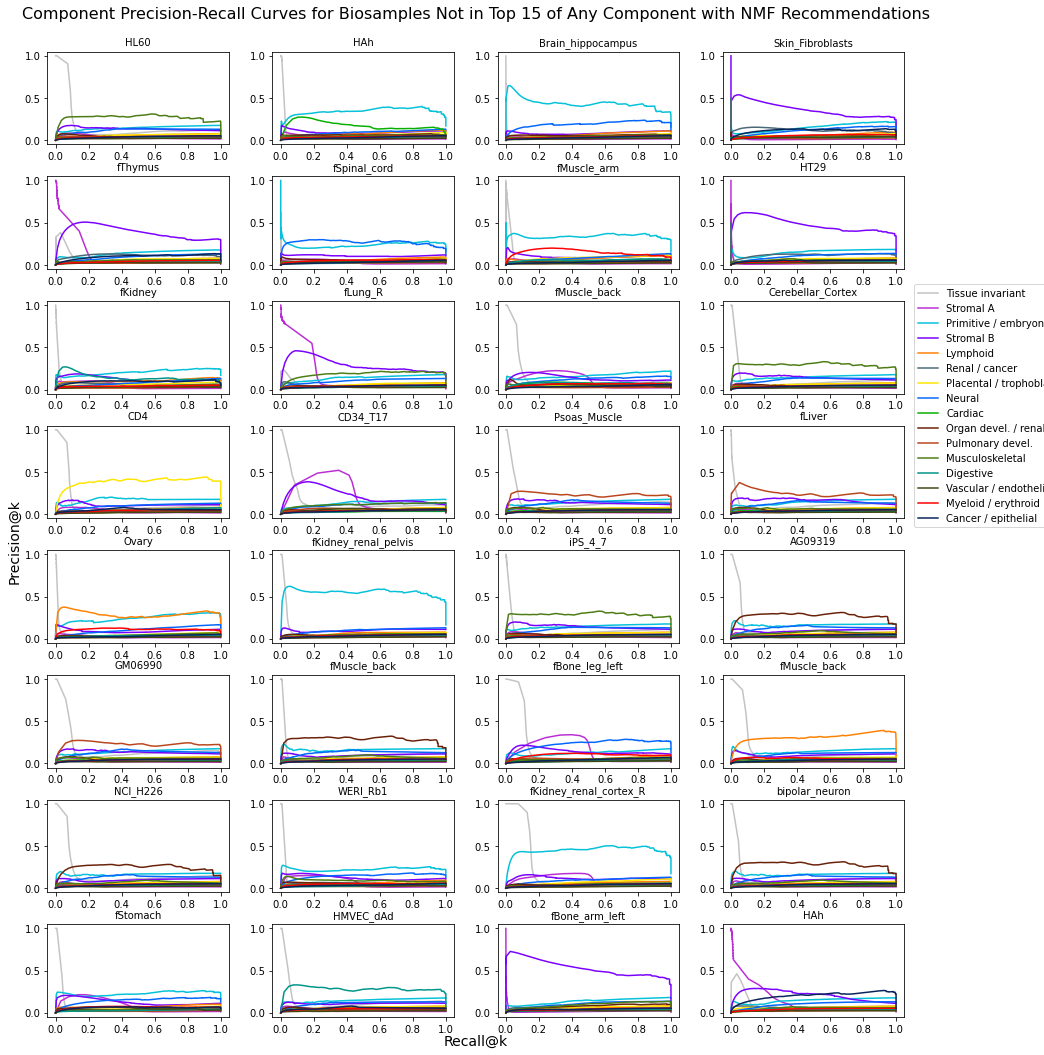

In [38]:
#
#Biosample names are not correct, results were pickled but names were not - see trello for correct names
#
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
    for i in range(len(comps)):
        ax.plot(not_top_biosample_recall[ind][i], not_top_biosample_precision[ind][i], color=color[i])
    ax.set_title(random_not_top_biosample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(0, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component Precision-Recall Curves for Biosamples Not in Top 15 of Any Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Component PR Curve AUC Values for Biosamples Not in Top 15 of Any Component with NMF Recommendations')

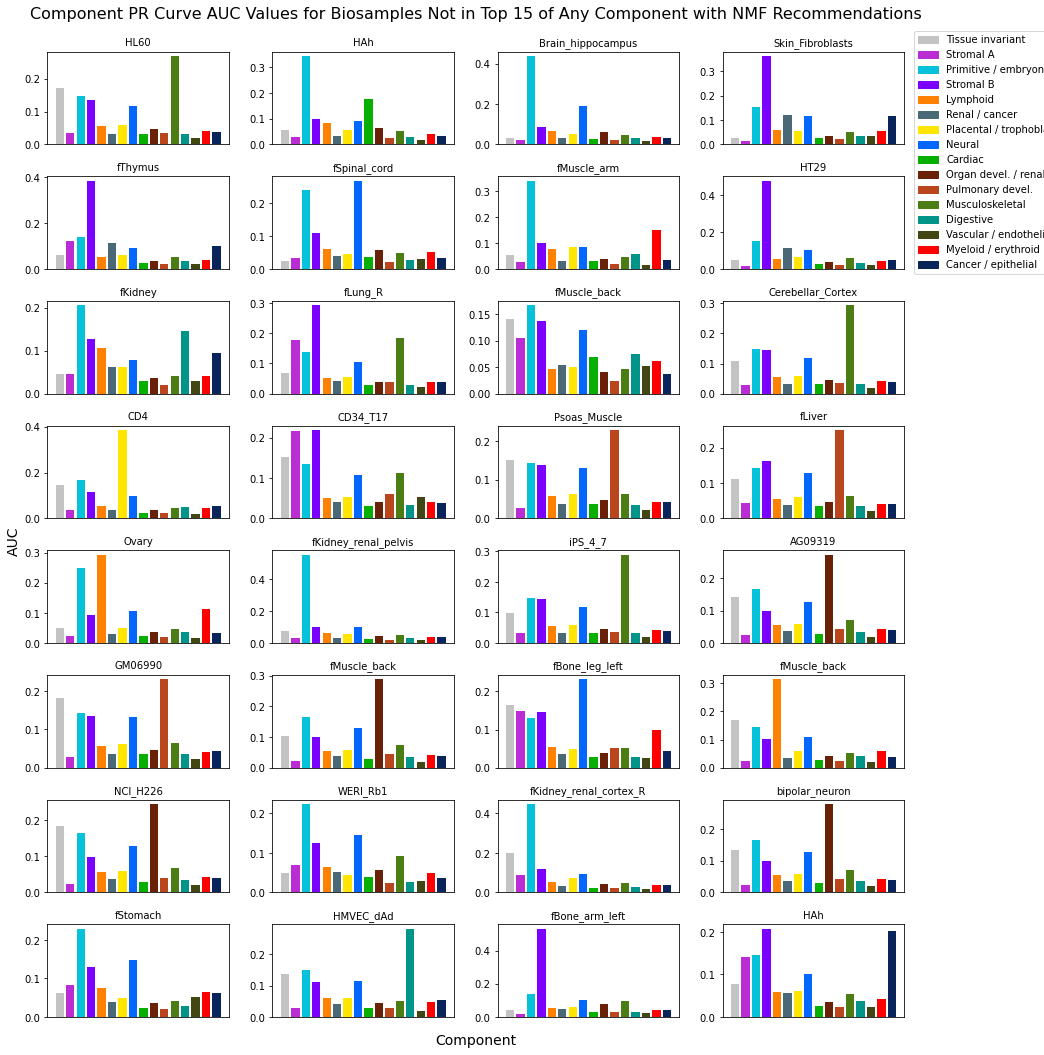

In [39]:
#
#Biosample names are not correct, results were pickled but names were not - see trello for correct names
#

fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
#     for i in range(len(comps)):
#         ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    ax.bar(comps, total_not_top_auc[ind], color=color)
    ax.set_title(random_not_top_biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.875, 0.74))
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(0, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Biosamples Not in Top 15 of Any Component with NMF Recommendations', fontsize=16, x=0.465, y=1.03)

In [74]:
component_precision_multiple_k(rec_info[0], 'Tissue invariant', [3000000])

['Tissue invariant' 'Tissue invariant' 'Tissue invariant' ... 'Neural'
 'Musculoskeletal' 'Renal / cancer']
[1 1 1 ... 0 0 0]
130849


(array([0.04361633]), array([1.]))

In [68]:
print(comp)

Cancer / epithelial


In [59]:
np.array(rec_info[0])

NameError: name 'rec_info' is not defined